In [ ]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml),
# ca notebook-ul sa functioneze indiferent de unde este rulat.
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_RAW = ROOT / "data" / "raw"              # AmesHousing.csv (fisierul original, nu e in Git)
DATA_PROCESSED = ROOT / "data" / "processed"  # df.csv, df_fe.csv (generate de notebook-uri, nu sunt in Git)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "src"))         # ca sa functioneze `from common import ...`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# citeste fisierul si il pune intr-un tabel pandas numit df (DataFrame)
# Citim fisierul original si il salvam ca df_raw (backup neatins)
df_raw = pd.read_csv(DATA_RAW / 'AmesHousing.csv', sep='\t')

# Cream copia de lucru 'df' pe care vom aplica toate transformarile si imputarile
df = df_raw.copy()
# nr de randuri, coloane, tipurile de date, numele fiecarei coloane, nr val null
df.info()
# afiseaza primele 5 randuri
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [2]:
# Verificam daca avem randuri duplicate
num_duplicates = df.duplicated().sum()
print(f"Nr de randuri duplicate: {num_duplicates}")

Nr de randuri duplicate: 0


Incarcarea si structura datelor

Datasetul contine 2930 de case vandute in Ames intre 2006 si 2010, descrise prin 82 de coloane.
Tinta pe care o vom prezice este SalePrice.
Mai jos clasificam variabilele, verificam valorile lipsa, cautam valori extreme

In [3]:
# Clasificare initiala a variabilelor dupa tip
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(include=['object', 'string']).columns

print(f"Nr caracteristici NUMERICE: {len(numeric_features)}")
print("COLOANE NUMERICE")
for idx, col in enumerate(numeric_features, 1):
    print(f"{idx:2d}. {col}")

print(f"Nr caracteristici CATEGORICE: {len(categorical_features)}")
print("COLOANE CATEGORICE")
for idx, col in enumerate(categorical_features, 1):
    print(f"{idx:2d}. {col}")


Nr caracteristici NUMERICE: 39
COLOANE NUMERICE
 1. Order
 2. PID
 3. MS SubClass
 4. Lot Frontage
 5. Lot Area
 6. Overall Qual
 7. Overall Cond
 8. Year Built
 9. Year Remod/Add
10. Mas Vnr Area
11. BsmtFin SF 1
12. BsmtFin SF 2
13. Bsmt Unf SF
14. Total Bsmt SF
15. 1st Flr SF
16. 2nd Flr SF
17. Low Qual Fin SF
18. Gr Liv Area
19. Bsmt Full Bath
20. Bsmt Half Bath
21. Full Bath
22. Half Bath
23. Bedroom AbvGr
24. Kitchen AbvGr
25. TotRms AbvGrd
26. Fireplaces
27. Garage Yr Blt
28. Garage Cars
29. Garage Area
30. Wood Deck SF
31. Open Porch SF
32. Enclosed Porch
33. 3Ssn Porch
34. Screen Porch
35. Pool Area
36. Misc Val
37. Mo Sold
38. Yr Sold
39. SalePrice
Nr caracteristici CATEGORICE: 43
COLOANE CATEGORICE
 1. MS Zoning
 2. Street
 3. Alley
 4. Lot Shape
 5. Land Contour
 6. Utilities
 7. Lot Config
 8. Land Slope
 9. Neighborhood
10. Condition 1
11. Condition 2
12. Bldg Type
13. House Style
14. Roof Style
15. Roof Matl
16. Exterior 1st
17. Exterior 2nd
18. Mas Vnr Type
19. Exter Qu

Clasificarea initiala a variabilelor dupa tipul de date

Pandas separa variabilele doar după tip: 39 numerice și 43 categorice. Clasificarea e grosiera, pentru ca unele coloane numerice sunt de fapt categorii sau identificatori.

In [4]:
# Coloane numerice ca tip, dar care sunt categorii pure -> le convertim la text
cat_as_num = ['MS SubClass', 'Mo Sold']
for col in cat_as_num:
    df[col] = df[col].astype(str)

# Coloane de identificare care nu aduc valoare predictiva -> le ignoram
id_cols = ['Order', 'PID']

# Identificam automat si curat variabilele:
numeric_features = [c for c in df.select_dtypes(include=[np.number]).columns if c not in id_cols]
categorical_features = list(df.select_dtypes(exclude=[np.number]).columns)

print(f"Numerice reale: {len(numeric_features)} | Categorice reale: {len(categorical_features)}")

print("COLOANE NUMERICE")
for idx, col in enumerate(numeric_features, 1):
    print(f"{idx:2d}. {col}")

print("COLOANE CATEGORICE")
for idx, col in enumerate(categorical_features, 1):
    print(f"{idx:2d}. {col}")

Numerice reale: 35 | Categorice reale: 45
COLOANE NUMERICE
 1. Lot Frontage
 2. Lot Area
 3. Overall Qual
 4. Overall Cond
 5. Year Built
 6. Year Remod/Add
 7. Mas Vnr Area
 8. BsmtFin SF 1
 9. BsmtFin SF 2
10. Bsmt Unf SF
11. Total Bsmt SF
12. 1st Flr SF
13. 2nd Flr SF
14. Low Qual Fin SF
15. Gr Liv Area
16. Bsmt Full Bath
17. Bsmt Half Bath
18. Full Bath
19. Half Bath
20. Bedroom AbvGr
21. Kitchen AbvGr
22. TotRms AbvGrd
23. Fireplaces
24. Garage Yr Blt
25. Garage Cars
26. Garage Area
27. Wood Deck SF
28. Open Porch SF
29. Enclosed Porch
30. 3Ssn Porch
31. Screen Porch
32. Pool Area
33. Misc Val
34. Yr Sold
35. SalePrice
COLOANE CATEGORICE
 1. MS SubClass
 2. MS Zoning
 3. Street
 4. Alley
 5. Lot Shape
 6. Land Contour
 7. Utilities
 8. Lot Config
 9. Land Slope
10. Neighborhood
11. Condition 1
12. Condition 2
13. Bldg Type
14. House Style
15. Roof Style
16. Roof Matl
17. Exterior 1st
18. Exterior 2nd
19. Mas Vnr Type
20. Exter Qual
21. Exter Cond
22. Foundation
23. Bsmt Qual
24. B

Clasificarea corectata dupa sens

Am impartit variabilele dupa sensul lor, nu doar dupa tipul de date din pandas:

- Numerice (35): cantitati masurabile: Lot Area, Gr Liv Area, Year Built, Yr Sold, SalePrice.
- Categorice (45): coloanele de tip text: MS Zoning, Neighborhood, MS SubClass, Mo Sold
- Ordinale: Overall Qual, Overall Cond (scara 1-10) le-am pastrat numerice, pentru că ordinea contează
- Excluse din features: Order, PID  (sunt doar identificatori, nu caracteristici ale casei)

De la 39/43 am ajuns la 35/45: 2 identificatori exclusi si 2 coloane mutate la categorice.

In [5]:
# Analizam valori lipsa (Missing Values)
# Afișam coloanele care au valori lipsa
total_missing = df.isnull().sum()
percent_missing = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Valori Lipsa': total_missing,
    'Procent (%)': percent_missing.round(2)
})

# Filtram doar coloanele cu date lipsa si le sortam descrescator
missing_df = missing_df[missing_df['Valori Lipsa'] > 0].sort_values(by='Valori Lipsa', ascending=False)

print(f"\nColoane cu valori lipsa: {len(missing_df)} din {df.shape[1]}")
print("\nToate coloanele cu valori lipsa:")
print(missing_df.head(len(missing_df)))


Coloane cu valori lipsa: 27 din 82

Toate coloanele cu valori lipsa:
                Valori Lipsa  Procent (%)
Pool QC                 2917        99.56
Misc Feature            2824        96.38
Alley                   2732        93.24
Fence                   2358        80.48
Mas Vnr Type            1775        60.58
Fireplace Qu            1422        48.53
Lot Frontage             490        16.72
Garage Qual              159         5.43
Garage Cond              159         5.43
Garage Yr Blt            159         5.43
Garage Finish            159         5.43
Garage Type              157         5.36
Bsmt Exposure             83         2.83
BsmtFin Type 2            81         2.76
Bsmt Cond                 80         2.73
Bsmt Qual                 80         2.73
BsmtFin Type 1            80         2.73
Mas Vnr Area              23         0.78
Bsmt Full Bath             2         0.07
Bsmt Half Bath             2         0.07
BsmtFin SF 1               1         0.03
BsmtFi

Tratarea Valorilor Lipsa (Missing Values Imputation)

In setul de date Ames Housing, valorile lipsa (NaN) au semnificatii diferite in functie de tipul si contextul fiecarui atribut. In acest dataset, pentru majoritatea coloanelor, NaN nu inseamna o eroare de masurare, ci indica faptul ca caracteristica nu exista (casa nu are piscina, garaj, subsol etc.). Eliminarea orbeasca a inregistrarilor sau a coloanelor ar duce la o pierdere masiva de informatie utila pentru modelele de Machine Learning.

Tratarea celor 27 de coloane cu valori lipsa a fost structurata in 5 categorii logice:

Categoria 1: Atribute Categoriale (Absenta unei Facilitati)

Pentru aceste variabile, valoarea NaN reprezinta absenta dotarii respective sau provine din faptul ca valoarea "None" a fost citita automat de Pandas ca NaN.

Exemple si Procente:

Pool QC (99.6%), Misc Feature (96.4%), Alley (93.2%), Fence (80.5%) - lipsesc aproape peste tot pentru ca foarte putine case au aceste facilitati.

Mas Vnr Type (60.6%) - apare cu multe valori lipsa deoarece valoarea "None" (fara zidarie) este interpretata implicit ca NaN.

Grupul Garage * (Garage Type, Garage Finish, Garage Qual, Garage Cond - 5.43%, adica 159 de case) si grupul Bsmt * (Bsmt Qual, Bsmt Cond, Bsmt Exposure, BsmtFin Type 1, BsmtFin Type 2) - lipsesc toate impreuna, reprezentand casele fara garaj, respectiv fara subsol.

Fireplace Qu (48.5%) - casele fara semineu.

Tratament si Justificare:
Inlocuim NaN cu categoria explicita 'None'. Nu le eliminam, deoarece aceasta completare permite modelelor de ML sa invete diferenta de pret dintre proprietatile care detin o anumita dotare si cele fara.

Categoria 2: Atribute Numerice legate de Suprafete si Capacitati

Atunci cand o casa nu are subsol, garaj sau zidarie decorativa, dimensiunea fizica, numarul de bai sau capacitatea aferenta sunt numeric egale cu 0.

Coloane vizate:
Mas Vnr Area, BsmtFin SF 1, BsmtFin SF 2, Bsmt Unf SF, Total Bsmt SF, Bsmt Full Bath, Bsmt Half Bath, Garage Cars, Garage Area.

Tratament si Justificare:
Inlocuim NaN cu valoarea numerica 0. Astfel se pastreaza continuitatea matematica si se previn erorile la calculul suprafetelor totale.

Categoria 3: Anul Constructiei Garajului (Garage Yr Blt - 5.43%)

Fiind o coloana numerica de tip an, inlocuirea cu 0 pentru cele 159 de case fara garaj ar distorsiona masiv scalarea datelor si ar afecta performanta modelelor liniare sau pe baza de distante.

Tratament si Justificare:

Am creat o variabila binara noua (Feature Engineering): Has_Garage (1 daca proprietatea are garaj, 0 daca nu).

Am inlocuit valorile NaN din Garage Yr Blt cu anul constructiei cladirii principale (Year Built).

Aceasta abordare este robusta si compatibila cu orice algoritm ML, deoarece indicatorul Has_Garage explica clar modelului ca anul garajului coincide cu cel al casei din lipsa unui garaj separat.

Categoria 4: Deschidere la Strada (Lot Frontage - 16.7%)

Lot Frontage este singura coloana din setul de date cu lipsuri reale (masuratori neefectuate / date care lipsesc la intamplare) si care necesita o imputare statistica adecvata.

Tratament si Justificare:
Am imputat valorile lipsa folosind mediana din cartierul aferent (Neighborhood). Dimensiunile terenurilor depind puternic de configuratia urbanistica a zonei/cartierului, motiv pentru care mediana pe cartier ofera o estimare mult mai precisa decat mediana pe intregul set de date.

Categoria 5: Sistemul Electric (Electrical)

Lipsește o singură valoare din întregul set de date.

Tratament si Justificare:
Am aplicat imputarea cu modul (cea mai frecventa categorie, 'SBrkr' - Standard Circuit Breakers), fiind metoda standard pentru valori lipsa izolate pe atribute categoriale.

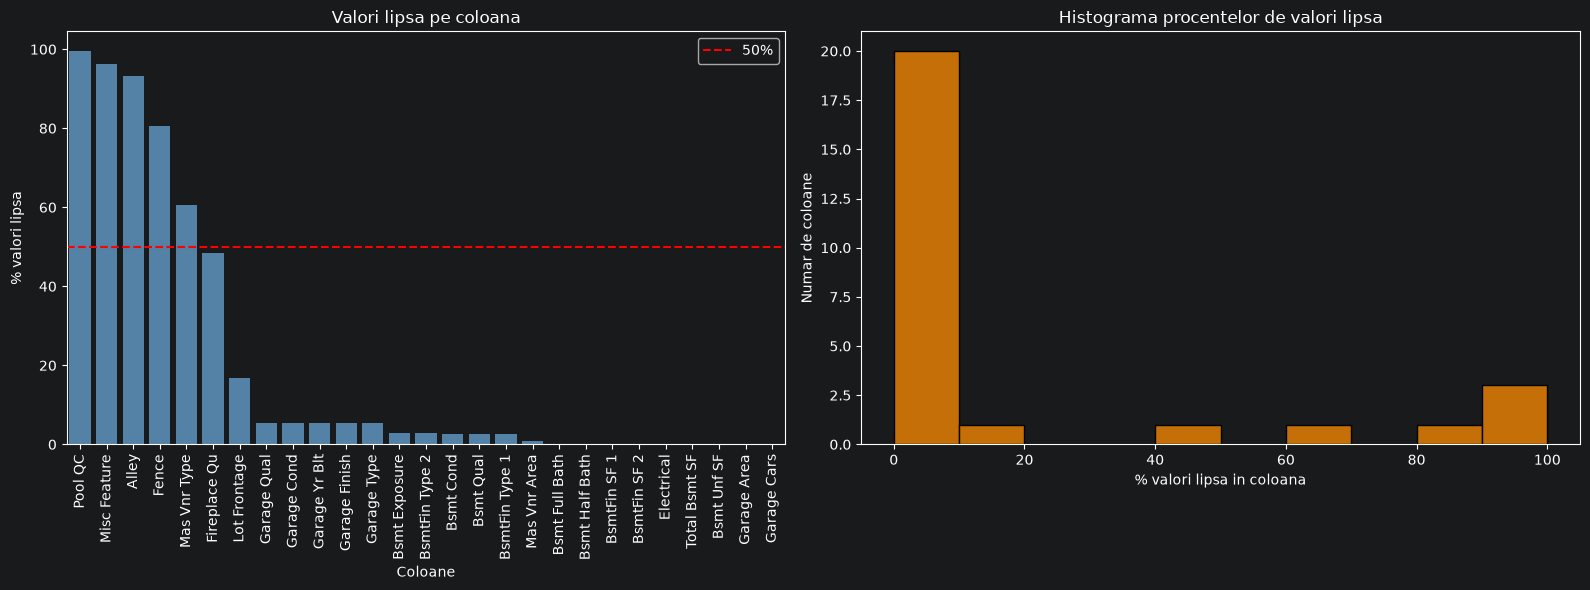

In [6]:
missing_pct = (df.isna().mean() * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Stanga: procentul de valori lipsa pe fiecare coloana
sns.barplot(x=missing_pct.index, y=missing_pct.values, color='steelblue', ax=axes[0])
axes[0].tick_params(axis='x', rotation=90)
axes[0].axhline(50, color='red', linestyle='--', label='50%')
axes[0].set_ylabel('% valori lipsa')
axes[0].set_xlabel('Coloane')
axes[0].set_title('Valori lipsa pe coloana')
axes[0].legend()

# Dreapta: histograma- cate coloane au un anumit procent de valori lipsa
sns.histplot(missing_pct, bins=10, binrange=(0, 100), color='darkorange', ax=axes[1])
axes[1].set_xlabel('% valori lipsa in coloana')
axes[1].set_ylabel('Numar de coloane')
axes[1].set_title('Histograma procentelor de valori lipsa')

plt.tight_layout()
plt.show()

Vizualizarea Grafica a Valorilor Lipsa
Doar 27 din cele 82 de coloane prezinta valori lipsa, iar distributia lor este puternic polarizata:

20 de coloane au sub 10% valori lipsa (sunt aproape complete).

5 coloane au peste 50% valori lipsa: Pool QC, Misc Feature, Alley, Fence si Mas Vnr Type.

2 coloane se afla in zona medie: Fireplace Qu (48.5%) si Lot Frontage (16.7%).

Histograma din dreapta confirma vizual aceasta separare in doua grupuri: majoritatea coloanelor au un procent insesizabil de lipsuri, in timp ce doar cateva sunt extrem de goale. Aceasta absenta masiva nu reprezinta o eroare de colectare, ci caracteristici pe care majoritatea caselor nu le au.

Interpretarea pe categorii de atribute:

Absenta facilitatilor speciale (peste 50% date lipsa):

Coloanele Pool QC, Misc Feature, Alley si Fence au cele mai mari procente de lipsuri, deoarece majoritatea proprietatilor nu dispun de piscina, anexe speciale, acces la alee secundara sau gard.

Atribute legate de subsol si garaj (procente reduse si sincronizate):

Grupurile de variabile pentru garaj (Garage Finish, Garage Qual, Garage Type) si subsol (Bsmt Qual, Bsmt Cond, Bsmt Exposure) au procente identice de valori lipsa. Aceasta sincronizare confirma ca datele lipsesc strict pentru casele fara subsol sau garaj.

Atribute cu lipsuri izolate:

Lot Frontage prezinta un procent moderat de valori lipsa (16.7%), necesitand imputare bazata pe contextul geografic (mediana pe cartier), in timp ce Mas Vnr Area sau Electrical au sub 1% date lipsa.

Aceasta analiza justifica direct strategia de imputare aplicata in pasul urmator, unde valorile NaN sunt inlocuite cu categoria None sau valoarea 0, evitand eliminarea inutila a observatiilor din setul de date.

In [7]:
# Verificare ani imposibili (datele sunt din 2006-2010)
print(df['Garage Yr Blt'].agg(['min', 'max']))
print(df[df['Garage Yr Blt'] > 2010][['Order', 'Year Built', 'Garage Yr Blt', 'Yr Sold']])

# 0. Cazuri inconsistente: lipseste o valoare, nu dotarea
m = df['Bsmt Qual'].notna() & df['Bsmt Exposure'].isna()
df.loc[m, 'Bsmt Exposure'] = df['Bsmt Exposure'].mode()[0]
m = df['BsmtFin Type 1'].notna() & df['BsmtFin Type 2'].isna()
df.loc[m, 'BsmtFin Type 2'] = df['BsmtFin Type 2'].mode()[0]

m = df['Garage Type'].notna() & df['Garage Finish'].isna()
for c in ['Garage Finish', 'Garage Qual', 'Garage Cond']:
    df.loc[m, c] = df.loc[df['Garage Type'].notna(), c].mode()[0]
for c in ['Garage Area', 'Garage Cars']:
    df[c] = df[c].fillna(df.groupby('Garage Type')[c].transform('median'))

# an garaj imposibil (2207) -> anul casei
df.loc[df['Garage Yr Blt'] > 2010, 'Garage Yr Blt'] = df['Year Built']

# 1. Categoria 1: Atribute Categoriale unde NaN = "Absenta Facilitatii" -> 'None'
cat_cols_none = [
    'Pool QC', 'Misc Feature', 'Alley', 'Fence', 'Mas Vnr Type', 'Fireplace Qu',
    'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond',
    'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2'
]
df[cat_cols_none] = df[cat_cols_none].fillna('None')

# 2. Categoria 2: Atribute Numerice legate de suprafete/capacitati inexistente -> 0
num_cols_zero = [
    'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
    'Bsmt Full Bath', 'Bsmt Half Bath', 'Garage Cars', 'Garage Area'
]
df[num_cols_zero] = df[num_cols_zero].fillna(0)

# 3. Categoria 3: Anul Garajului -> Flag binar + Imputare cu anul casei (Year Built)
df['Has_Garage'] = (df['Garage Type'] != 'None').astype(int)
df['Garage Yr Blt'] = df['Garage Yr Blt'].fillna(df['Year Built'])

# 4. Categoria 4: Lot Frontage -> Imputare cu mediana pe cartier (Neighborhood)
df['Lot Frontage'] = df.groupby('Neighborhood')['Lot Frontage'].transform(lambda x: x.fillna(x.median()))
# Fallback cu mediana generala in cazul in care exista un cartier fara nicio valoare
df['Lot Frontage'] = df['Lot Frontage'].fillna(df['Lot Frontage'].median())

# 5. Categoria 5: Electrical -> Imputare cu modul (cea mai frecventa valoare)
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

print(f"Numar total de valori lipsa ramase in dataset: {df.isnull().sum().sum()}")

min    1895.0
max    2207.0
Name: Garage Yr Blt, dtype: float64
      Order  Year Built  Garage Yr Blt  Yr Sold
2260   2261        2006         2207.0     2007
Numar total de valori lipsa ramase in dataset: 0


Justificarea tratarii valorilor lipsa

Pentru tratarea datelor lipsa am aplicat o strategie adaptata fiecarui tip de caracteristica, astfel incat sa nu pierdem informatii valoroase.

In cazul celor 15 coloane categorice (cum ar fi Alley, Pool QC, Fence, coloanele de tip Garage *, Bsmt *, Fireplace Qu, Mas Vnr Type si Misc Feature), am inlocuit valorile lipsa cu textul 'None'. In acest set de date, o valoare NaN nu reprezinta o eroare de colectare, ci indica faptul ca proprietatea respectiva nu are piscina, alee, gard, garaj sau subsol. Aceasta informatie despre inexistenta unei facilitati este foarte utila pentru model.

Exista totusi cateva cazuri izolate, inconsistente, in care lipsa unei valori nu inseamna absenta dotarii, ci o completare omisa in date. Le-am identificat comparand coloanele din aceeasi grupa (de exemplu, o casa cu Bsmt Qual completat, deci cu subsol, dar cu Bsmt Exposure lipsa) si le-am corectat inainte de a aplica regula 'None', pentru ca altfel ar fi fost marcate gresit ca "fara subsol" sau "fara garaj":
- Subsol: 3 case au Bsmt Qual completat, dar Bsmt Exposure lipsa, iar o casa are BsmtFin Type 1 completat, dar BsmtFin Type 2 lipsa. Am completat valorile lipsa cu cea mai frecventa valoare a coloanei ('No' pentru Bsmt Exposure, 'Unf' pentru BsmtFin Type 2).
- Garaj: 2 case au Garage Type completat, dar Garage Finish, Garage Qual si Garage Cond lipsa. Le-am completat cu cea mai frecventa valoare calculata doar pe casele cu garaj. Una dintre ele avea lipsa si Garage Area si Garage Cars, pe care le-am completat cu mediana garajelor de acelasi tip, pentru ca o casa cu garaj nu poate avea suprafata 0.
Aceste corectii afecteaza doar 6 case din 2930, deci impactul asupra modelului este mic, dar evita contradictii in date.

Pentru coloana Electrical, avand o singura valoare lipsa in tot setul de date, am ales imputarea cu moda (cea mai frecventa categorie), deoarece impactul asupra rezultatelor este neglijabil.

La Lot Frontage, am completat valorile lipsa folosind mediana calculata la nivelul fiecarui cartier (Neighborhood). Aceasta alegere se bazeaza pe faptul ca terenurile din acelasi cartier au dimensiuni si fronturi stradale similare, iar mediana este o masura robusta care nu este influentata de valorile extreme.

In privinta coloanei Garage Yr Blt, am completat anii lipsa cu valoarea din Year Built, pornind de la ipoteza ca, de cele mai multe ori, garajul este construit odata cu casa.

Pentru cele 9 coloane numerice (precum Garage Area, Total Bsmt SF, Mas Vnr Area sau numarul de bai de la subsol), am inlocuit valorile lipsa cu 0. Lipsa acestei facilitati inseamna ca suprafata sau numarul respectiv de elemente este nul.

Asa cum se poate observa, nu am eliminat nicio coloana din setul de date, nici macar pe cele care aveau peste 90% valori lipsa, deoarece faptul ca o casa "nu are piscina" reprezinta o informatie complet valida. Eventuala eliminare a unor variabile va fi analizata ulterior, in etapa de selectie a caracteristicilor. In urma acestei etape, in setul de date nu mai ramane nicio valoare lipsa.

=== Statistici Descriptive SalePrice ===
count      2930.00
mean     180796.06
std       79886.69
min       12789.00
25%      129500.00
50%      160000.00
75%      213500.00
max      755000.00
Name: SalePrice, dtype: float64

Skewness: 1.74
Kurtosis: 5.12


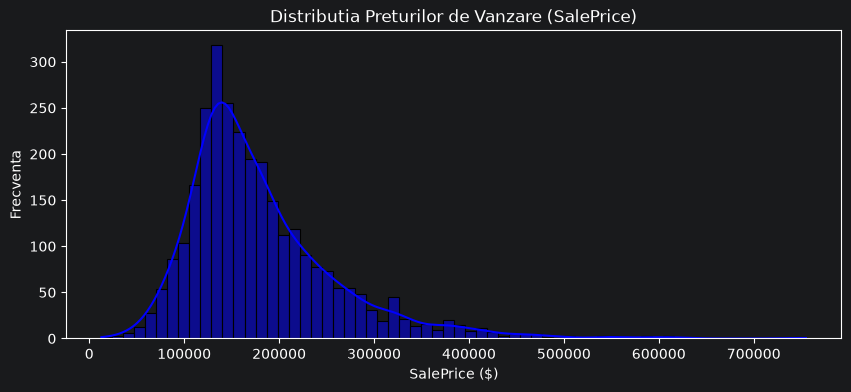

In [8]:
# 1. Statistici complete (medie, mediana, deviatie standard, quartile)
print("=== Statistici Descriptive SalePrice ===")
print(df['SalePrice'].describe().round(2))

# 2. Asimetrie (Skewness) si Boltire (Kurtosis)
print(f"\nSkewness: {df['SalePrice'].skew():.2f}")
print(f"Kurtosis: {df['SalePrice'].kurt():.2f}")

# 3. Vizualizare pentru Forma Distributiei si Outliers
plt.figure(figsize=(10, 4))
sns.histplot(df['SalePrice'], kde=True, color='blue')
plt.title('Distributia Preturilor de Vanzare (SalePrice)')
plt.xlabel('SalePrice ($)')
plt.ylabel('Frecventa')
plt.show()

Analiza Univariata a Variabilei Tinta (SalePrice)
Pentru a intelege caracteristicile si distributia pretului de vanzare (SalePrice), am analizat indicatorii statistici principali si forma graficului aferent.

Statistici Descriptive Cheie

Media (Mean): $180,796.06:  pretul mediu de vanzare al unei case din setul de date.
Mediana (50% / Q2): $160,000.00: valoarea centrala a datelor (50% din case se vand sub acest pret, iar 50% peste).
Deviatia Standard (Std): $79,886.69: indica o dispersie considerabila a preturilor fata de medie.
Interval de Pret (Min - Max): Preturile variaza de la un minim de $12,789.00 pana la un maxim de $755,000.00.
Intervalul Interquartil (IQR):
25% (Q1): $129,500.00
75% (Q3): $213,500.00
Interpretare: Jumatate din totalul caselor tranzactionate au preturi cuprinse intre $129,500 si $213,500.

Forma Distributiei si Asimetria

Asimetria (Skewness = 1.74):
O valoare pozitiva (mai mare decat 1) indica o distributie asimetrica spre dreapta (Right-Skewed). Majoritatea caselor au preturi concentrate in zona medie ($120,000 - $200,000), dar exista o "coada" de proprietati scumpe care trage media ($180,796) peste mediana ($160,000).

Boltirea (Kurtosis = 5.12):
Valoarea de 5.12 (peste nivelul unei distributii normale de 3) arata o distributie leptocurtica (varf ascutit si cozi groase). Acest lucru confirma prezenta unor valori aberante extreme (outliers) in zona preturilor foarte mari (peste $400,000 - $700,000).

Concluzie si Implicatii pentru Machine Learning

Prezenta Outliers: Exista cateva case extrem de scumpe (pana la $755,000) care pot distorsiona modelele liniare.

Recomandare de Transformare: Din cauza asimetriei accentuate (Skewness 1.74), la etapele viitoare de Machine Learning (L2) se poate lua in considerare aplicarea unei transformari logaritmice (np.log1p(SalePrice)) pentru a aduce distributia mai aproape de forma normala (Gaussian) si pentru a imbunatati performanta algoritmilor.

In [9]:
# 1. Statistici descriptive pentru variabilele numerice reprezentative
print("=== Statistici Descriptive: Variabile Numerice ===")
print(df[['Gr Liv Area', 'Total Bsmt SF', 'Lot Area', 'Year Built']].describe().round(2))

print("\n" + "="*50 + "\n")

# 2. Frecvente pentru variabila ordinala Overall Qual
print("=== Frecvente: Overall Qual ===")
print(df['Overall Qual'].value_counts().sort_index())

print("\n" + "="*50 + "\n")

# 3. Frecvente pentru variabilele categoriale reprezentative
print("=== Frecvente: Incadrare Urbanistica (MS Zoning) ===")
print(df['MS Zoning'].value_counts())

print("\n" + "="*50 + "\n")

print("=== Top 10 Cartiere (Neighborhood) ===")
print(df['Neighborhood'].value_counts().head(10))

print("\n" + "="*50 + "\n")

print("=== Frecvente: Conditia de Vanzare (Sale Condition) ===")
print(df['Sale Condition'].value_counts())

=== Statistici Descriptive: Variabile Numerice ===
       Gr Liv Area  Total Bsmt SF   Lot Area  Year Built
count      2930.00        2930.00    2930.00     2930.00
mean       1499.69        1051.26   10147.92     1971.36
std         505.51         440.97    7880.02       30.25
min         334.00           0.00    1300.00     1872.00
25%        1126.00         793.00    7440.25     1954.00
50%        1442.00         990.00    9436.50     1973.00
75%        1742.75        1301.50   11555.25     2001.00
max        5642.00        6110.00  215245.00     2010.00


=== Frecvente: Overall Qual ===
Overall Qual
1       4
2      13
3      40
4     226
5     825
6     732
7     602
8     350
9     107
10     31
Name: count, dtype: int64


=== Frecvente: Incadrare Urbanistica (MS Zoning) ===
MS Zoning
RL         2273
RM          462
FV          139
RH           27
C (all)      25
I (all)       2
A (agr)       2
Name: count, dtype: int64


=== Top 10 Cartiere (Neighborhood) ===
Neighborhood
NAmes 

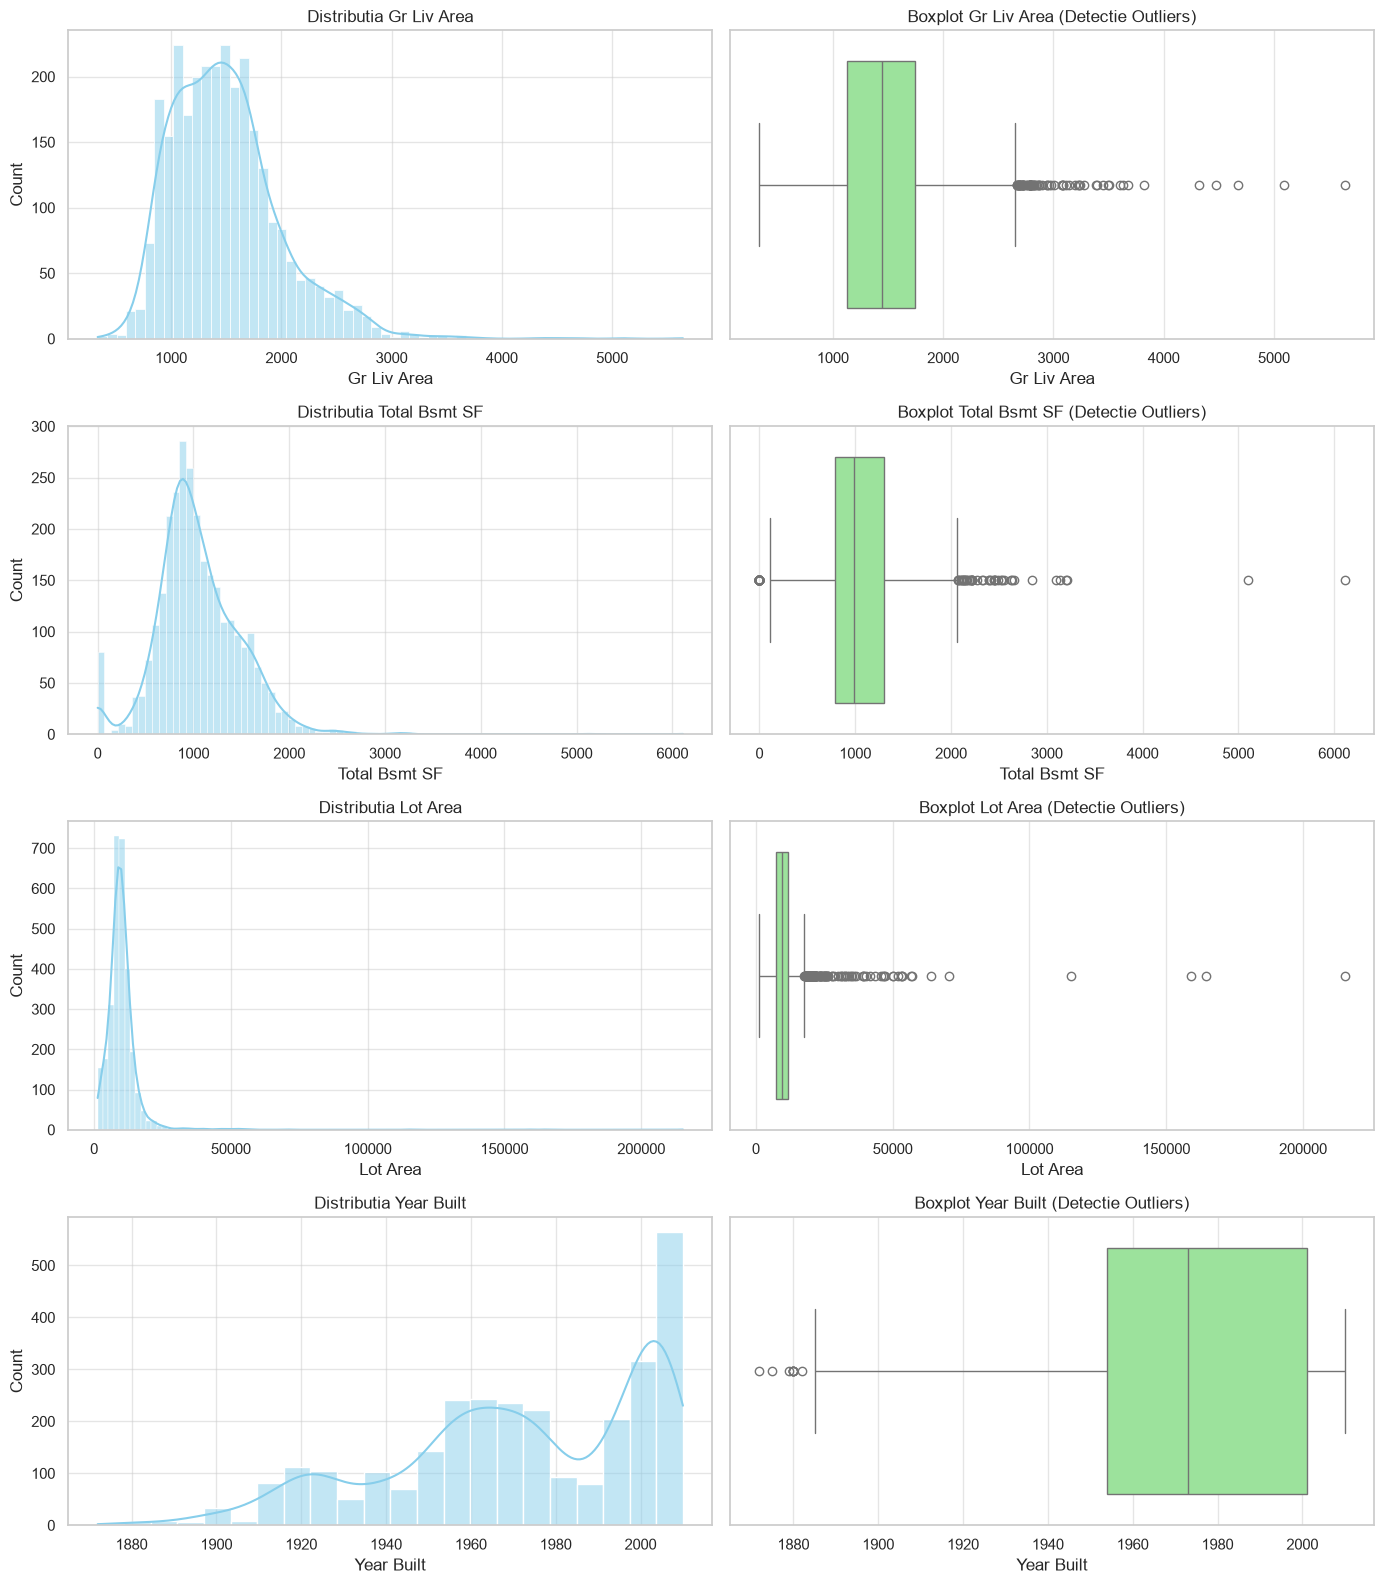

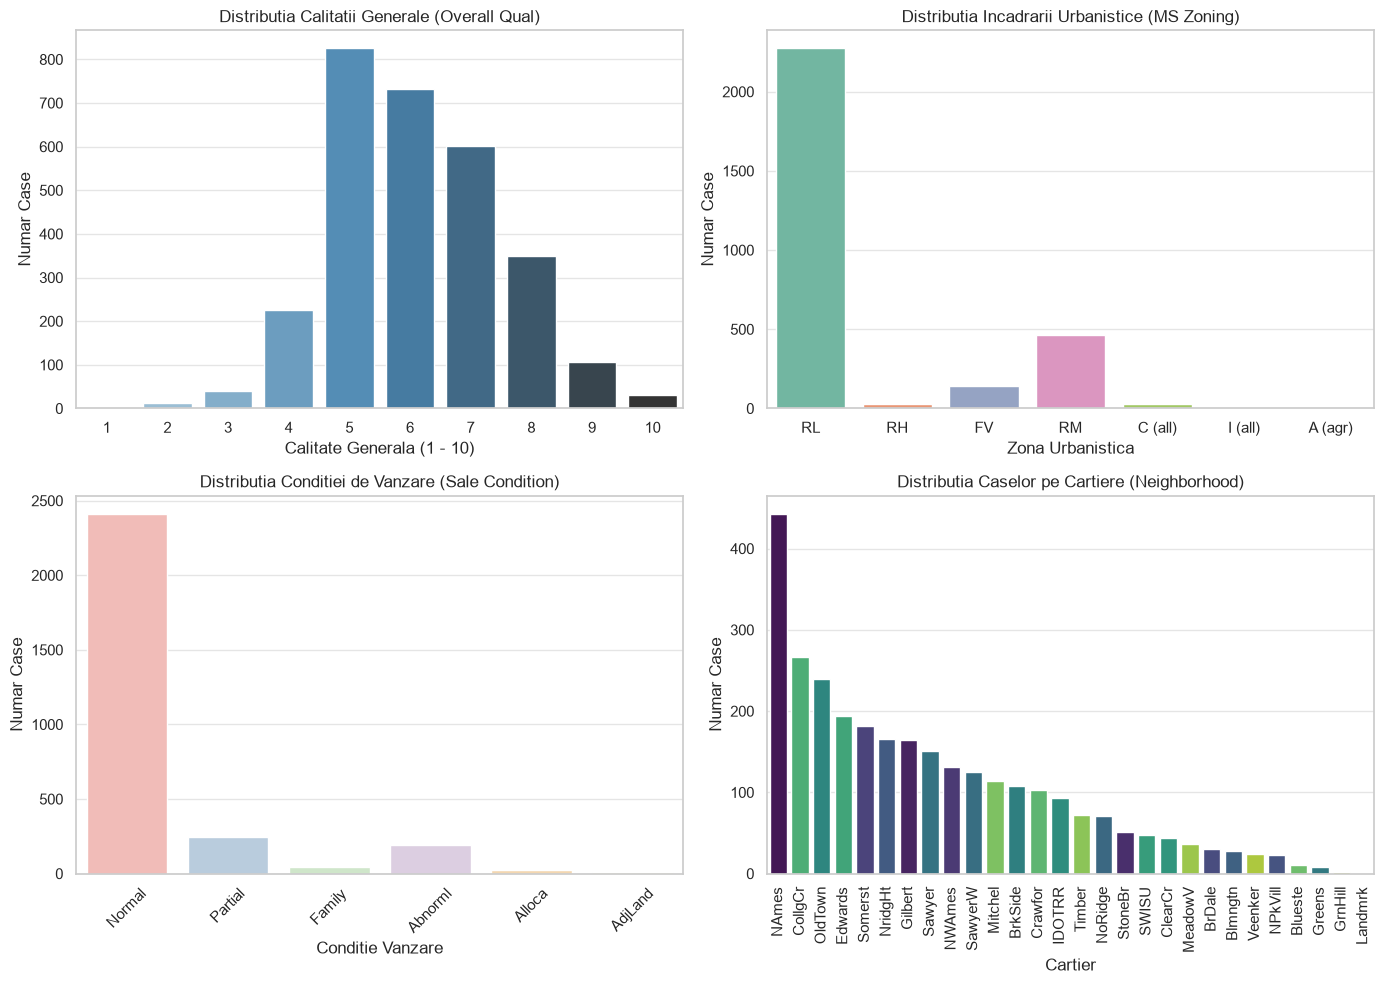

In [10]:
# Configurare stil grafice
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 10)

# Subplots pentru variabilele numerice (Histograme + Boxplots)
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

num_cols = ['Gr Liv Area', 'Total Bsmt SF', 'Lot Area', 'Year Built']

for i, col in enumerate(num_cols):
    # Histogram/KDE
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Distributia {col}')

    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Boxplot {col} (Detectie Outliers)')

plt.tight_layout()
plt.show()

# Subplots pentru variabilele ordinale si categoriale
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall Qual
sns.countplot(data=df, x='Overall Qual', ax=axes[0, 0], hue='Overall Qual', palette='Blues_d', legend=False)
axes[0, 0].set_title('Distributia Calitatii Generale (Overall Qual)')
axes[0, 0].set_xlabel('Calitate Generala (1 - 10)')
axes[0, 0].set_ylabel('Numar Case')

# MS Zoning
sns.countplot(data=df, x='MS Zoning', ax=axes[0, 1], hue='MS Zoning', palette='Set2', legend=False)
axes[0, 1].set_title('Distributia Incadrarii Urbanistice (MS Zoning)')
axes[0, 1].set_xlabel('Zona Urbanistica')
axes[0, 1].set_ylabel('Numar Case')

# Sale Condition
sns.countplot(data=df, x='Sale Condition', ax=axes[1, 0], hue='Sale Condition', palette='Pastel1', legend=False)
axes[1, 0].set_title('Distributia Conditiei de Vanzare (Sale Condition)')
axes[1, 0].set_xlabel('Conditie Vanzare')
axes[1, 0].set_ylabel('Numar Case')
axes[1, 0].tick_params(axis='x', rotation=45)

# Neighborhood (Top Cartiere)
sns.countplot(data=df, x='Neighborhood', order=df['Neighborhood'].value_counts().index, ax=axes[1, 1], hue='Neighborhood', palette='viridis', legend=False)
axes[1, 1].set_title('Distributia Caselor pe Cartiere (Neighborhood)')
axes[1, 1].set_xlabel('Cartier')
axes[1, 1].set_ylabel('Numar Case')
axes[1, 1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

Selectia si Analiza Univariata a Variabilelor Predictor Reprezentative
Pentru a asigura o analiza riguroasa si eficienta, am evitat includerea redundanta a tuturor celor 82 de coloane din setul de date. Am selectat un grup restrans dar complet de variabile reprezentative, acoperind toate dimensiunile fizice, calitative si economice ale evaluarii imobiliare.

Justificarea Selectiei Variabilelor

Gr Liv Area (Suprafata Locuibila peste Sol):

Motivul alegerii: Reprezinta cel mai important indicator al spatiului util de locuit. Am omis deliberat variabile precum 1st Flr SF sau 2nd Flr SF la aceasta etapa univariata pentru a evita redundanta si multicoliniaritatea, intrucat Gr Liv Area insumeaza deja aceste suprafete.

Total Bsmt SF (Suprafata Totala a Subsolului):

Motivul alegerii: Capteaza dimensiunea spatiului secundar (subteran), care adauga valoare semnificativa proprietatii, avand o distributie diferita fata de suprafata locuibila deasupra solului.

Lot Area (Suprafata Terenului):

Motivul alegerii: Este reprezentanta dimensiunii terenului si este esentiala pentru identificarea valorilor extreme (outliers masivi), fiind mentionata explicit si in ghidul de laborator.

Year Built (Anul Constructiei):

Motivul alegerii: Este principala variabila temporala care masoara vechimea cladirii si uzura fizica a acesteia.

Overall Qual (Calitatea Generala):

Motivul alegerii: Este o variabila ordinala (1-10) si reprezinta cel mai puternic predictor statistic pentru pretul de vanzare din intregul set de date Ames Housing.

MS Zoning (Incadrarea Urbanistica):

Motivul alegerii: Ofera cadrul macro-locational, diferentiind proprietatile rezidentiale de cele comerciale sau cu densitate scazuta/medie.

Neighborhood (Cartierul):

Motivul alegerii: Ofera cadrul micro-locational. In imobiliare, amplasamentul exact este critic, iar aceasta variabila are cea mai mare diversitate categoriala (28 de categorii).

Sale Condition (Conditiile de Vanzare):

Motivul alegerii: Permite identificarea vanzarilor speciale (executari silite, tranzactii intre rude sau case nefinalizate) care pot distorsiona pretul real al pietei.

Interpretarea Distributiilor si a Statisticilor

Variabile Numerice:

Gr Liv Area:

Distributie usor asimetrica spre dreapta, majoritatea caselor avand intre 1,000 si 1,800 sq ft.

Boxplot-ul indica valori extreme (outliers) cu suprafete peste 4,000 sq ft.

Total Bsmt SF:

Prezinta un varf la valoarea 0 (case fara subsol), iar pentru restul observatiilor urmeaza o distributie aproape normala concentrata intre 800 si 1,400 sq ft.

Lot Area:

Distributie puternic asimetrica spre dreapta. Majoritatea terenurilor au sub 15,000 sq ft, dar exista cativa outliers masivi cu terenuri de peste 40,000 - 100,000 sq ft.

Year Built:

Arata un trend istoric de constructie din 1872 pana in 2010, cu varfuri majore de dezvoltare imobiliara dupa anul 1950 si in anii 2000.

Variabile Categoriale si Ordinale:

Overall Qual:

Distributie simetrica (clopotul lui Gauss), majoritatea proprietatilor incadrandu-se la note medii de 5, 6 si 7.

MS Zoning:

Categoria RL (Residential Low Density) domina clar setul de date, urmata de RM (Residential Medium Density). Alte zone precum Commercial sunt extrem de rare.

Neighborhood:

Distributie neuniforma. Cartiere precum NAmes, CollgCr si OldTown au cel mai mare volum de tranzactii, in timp ce cartiere precum Greenhill au foarte putine observatii.

Sale Condition:

Peste 80% din tranzactii s-au desfasurat in conditii normale de piata (Normal). Categoriile Partial (constructii noi) si Abnorml (vanzari atipice) reprezinta minoritati importante ce necesita atentie la modelare.

Primele semne de valori extreme
Comparand max cu min si cu media, apar cateva suspiciuni:

Lot Area: media este de aproximativ 10,148, dar maximul este de 215,245, iar abaterea standard e mare. Probabil exista loturi extrem de mari.

Gr Liv Area: media este de aproximativ 1,500, iar maximul este de 5,642, mult peste restul caselor.

SalePrice: valorile merg de la 12,789 la 755,000, deci distributia are o coada lunga spre case scumpe.

Year Built: minimul este 1872, deci exista case foarte vechi, dar plauzibile.

Functia describe doar sugereaza aceste cazuri. Le confirmam vizual cu boxplots si le numaram cu regula IQR in sectiunea despre outlieri.

La variabilele categorice, indicatorii top si freq arata dezechilibre. De exemplu, Street are aproape toate casele cu valoarea Pave, deci aproape nu aduce informatie si e un candidat la eliminare.

Structura: 2930 de case, 82 coloane (35 numerice, 45 categorice, 2 identificatori exclusi). Fara duplicate.

Valori lipsa: 27 de coloane afectate. Majoritatea lipsurilor inseamna "caracteristica nu exista", asa ca le-am completat cu 'None' sau 0. Doar Lot Frontage a necesitat imputare reala (mediana pe cartier).

Variabila tinta: SalePrice este asimetrica spre dreapta, iar log-transformarea o face aproape normala. Recomandare: se prezice log(SalePrice).

Outlieri: am eliminat 9 observatii extreme (2921 ramase) si am pastrat restul valorilor mari, care sunt reale.

Candidati Initiali pentru Eliminare (Analiza Univariata)

In urma analizei univariate si a inspectiei initiale a caracteristicilor, au fost identificati urmatorii candidati pentru eliminare:

Identificatori tehnici fara valoare predictiva:

Order si PID: Sunt chei primare si numere de identificare administrative care nu influenteaza valoarea de piata a proprietatilor.

Variabile quasi-constante (Varianta aproape nula):

Street si Utilities: Peste 99% din observatii apartin unei singure categorii (de exemplu, aproape toate casele au acces la alee pavata si utilitati complete). Deoarece nu exista variatie intre observatii, aceste coloane nu aduc informatie utila pentru modelele de predictie.

Nota: Decizia finala privind eventuala eliminare a altor caracteristici (cum ar fi cele cu un procent extrem de ridicat de lipsuri sau cele puternic multicoliniare) va fi luata dupa finalizarea analizei bivariate si a matricii de corelatie.

In [11]:
df.to_csv(DATA_PROCESSED / 'df.csv', index=False)
print('Salvat: df.csv', df.shape)

Salvat: df.csv (2930, 83)
